<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h1>Riding the Demand Curve</h1>
<h3>Hourly Bike Rental Forecasting and Demand Drivers for Cook County</h3>

<strong>Prepared for:</strong> Cook County Planning and Development Department<br>
<strong>Prepared by:</strong> [Your name]<br>
<strong>Course:</strong> DAT-7470 Business Analysis with Structured Data - Final Assignment<br>
Hult International Business School<br>
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h2>Analysis Introduction</h2>

Cook County's Planning and Development Department asked us a practical question: how many bikes will people rent in a given hour, and what pushes that number up or down? The answer has direct operational value, because every hour in which bikes and riders are mismatched is either a lost trip or an idle asset that still has to be maintained. The dataset contains 678 hourly records from March to June, combining the calendar (month, day of the week, hour and holiday) with seven weather measurements and the number of rentals in each hour. Two features of the data shape every conclusion in this report: it is recorded by the hour rather than by the day, and it covers only spring and early summer, so it says nothing about Chicago's winter. We answer three questions in turn: whom the system really serves, which weather factor matters most, and when demand is low enough to take bikes off the street for maintenance. We then compare linear and tree-based models and recommend one for real-time use, selected on testing R-square and held to a train-test gap of no more than 0.05. In short, the evidence describes a commuter system whose busiest hour of the week is 6 pm on a working day. Temperature is the weather factor that matters most, and the quietest maintenance window is 2 to 6 am on cool nights. The recommended linear model explains about 83% of the hour-to-hour variation in rentals on hours it had never seen. Each section closes with what the finding means for the County's planning and operations.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part I: Setup</h2>
<h4>Imports</h4>

In [1]:
# importing libraries
import os                                              # locating the dataset
import numpy as np                                     # mathematical essentials
import pandas as pd                                    # data science essentials
import matplotlib.pyplot as plt                        # data visualization
import seaborn as sns                                  # enhanced data visualization
from sklearn.model_selection import train_test_split   # train-test split
from sklearn.model_selection import cross_val_score    # cross-validation inside the training set
from sklearn.model_selection import KFold              # folds for cross-validation
from sklearn.linear_model import LinearRegression      # linear regression
from sklearn.tree import DecisionTreeRegressor         # regression trees
from sklearn.tree import plot_tree                     # tree plots
from sklearn.preprocessing import StandardScaler       # standardizing x-features
import warnings                                        # warnings from code


# keeping the output free of version warnings
warnings.filterwarnings("ignore")

<h4>Loading the Dataset</h4>The notebook looks for <code>bike_rentals.xlsx</code> next to the notebook first, then in a <code>datasets</code> folder, and finally in Google Colab's <code>/content</code> folder.

In [2]:
# candidate locations for the dataset (local folder, datasets folder, Google Colab)
file = None
for path in ['./bike_rentals.xlsx', './datasets/bike_rentals.xlsx', '/content/bike_rentals.xlsx']:
    if os.path.exists(path):
        file = path
        break


# in Google Colab only: open an upload button if the file has not been uploaded yet
if file is None:
    from google.colab import files
    file = list(files.upload().keys())[0]


# reading the file into Python
bikes = pd.read_excel(io = file)


# checking the first rows
bikes.head(n = 5)

,ID,Month,Day of Week,Hour,Temperature,Humidity,Wind Speed,Visibility,Dew Point Temperature,UV Index,Rainfall,Snowfall,Seasons,Holiday,RENTALS
0,1,Mar,Wednesday,1,2.1,97,0.2,859,1.6,0.00,0.0,0,Spring,Yes,158
1,2,Mar,Wednesday,2,2.0,97,1.0,580,1.5,0.00,0.0,0,Spring,Yes,191
2,3,Mar,Wednesday,4,1.6,97,1.1,636,1.1,0.00,0.0,0,Spring,Yes,31
3,4,Mar,Wednesday,5,2.2,97,2.9,362,1.7,0.00,0.0,0,Spring,Yes,12
4,5,Mar,Wednesday,12,0.5,46,4.7,1172,-9.8,2.49,0.0,0,Spring,Yes,333


<h4>User-Defined Functions</h4>Three functions keep the analysis consistent: every model is trained and scored with the same split, and the tree paths are translated into readable rules.

In [3]:
########################################
# run_model
########################################
def run_model(model, x_data, y_data, name):
    """
    Applies the model building framework (split, fit, predict, score) with the
    course split settings and returns a one-row summary plus the fitted model.

    PARAMETERS
    ----------
    model  : unfitted scikit-learn model (LinearRegression or DecisionTreeRegressor)
    x_data : DataFrame, x-features
    y_data : Series, response variable
    name   : str, label for the comparison table
    """

    # same split for every model so that scores are comparable
    x_train, x_test, y_train, y_test = train_test_split(x_data,
                                                        y_data,
                                                        test_size    = 0.35,
                                                        random_state = 702)

    # 5-fold cross-validation INSIDE the training set (used to choose models without the test set)
    cv_score = cross_val_score(model, x_train, y_train,
                               cv = KFold(n_splits = 5, shuffle = True, random_state = 702)).mean()

    # FITTING on the training set only
    model.fit(x_train, y_train)

    # SCORING with R-square on both sets
    train_score = model.score(x_train, y_train)
    test_score  = model.score(x_test,  y_test)

    # gap above 0.05 means the model does not generalize reliably
    summary = {'Model'              : name,
               'X-Features'         : x_data.shape[1],
               'CV R2 (train only)' : round(cv_score,    4),
               'Training R2'        : round(train_score, 4),
               'Testing R2'         : round(test_score,  4),
               'Abs. Gap'           : round(abs(train_score - test_score), 4)}

    return summary, model


########################################
# standardized_weather_model
########################################
def standardized_weather_model(x_data, y_data, weather_cols, name):
    """
    Fits a LinearRegression where the weather columns are standardized with a
    scaler fitted on the TRAINING set only. Returns the summary row, the
    standardized weather coefficients and the testing R-square lost when each
    weather factor is removed.
    """

    # same split as every other model in the notebook
    x_train, x_test, y_train, y_test = train_test_split(x_data, y_data,
                                                        test_size = 0.35, random_state = 702)

    # scaler learns means and standard deviations from training data only
    scaler = StandardScaler().fit(x_train[weather_cols])
    x_train, x_test = x_train.copy(), x_test.copy()
    x_train[weather_cols] = scaler.transform(x_train[weather_cols])
    x_test[weather_cols]  = scaler.transform(x_test[weather_cols])

    # fitting and scoring
    model      = LinearRegression().fit(x_train, y_train)
    test_score = model.score(x_test, y_test)
    summary    = {'Model'          : name,
                  'Training R2'    : round(model.score(x_train, y_train), 4),
                  'Testing R2'     : round(test_score, 4)}

    # coefficients of the weather columns only (calendar controls are not ranked)
    coefs = pd.Series(model.coef_, index = x_data.columns)[weather_cols]

    # drop-one check: refit without each weather factor and measure the loss in testing R-square
    loss = pd.Series({factor : test_score - LinearRegression()
                                             .fit(x_train.drop(columns = factor), y_train)
                                             .score(x_test.drop(columns = factor), y_test)
                      for factor in weather_cols})

    return summary, coefs, loss


########################################
# leaf_rules
########################################
def leaf_rules(tree, feature_names):
    """
    Returns a dictionary {leaf id : list of conditions} describing the path
    from the root of a fitted DecisionTreeRegressor to each terminal node.
    """

    structure = tree.tree_
    rules     = {}

    # walking the tree from the root, carrying the conditions met so far
    def walk(node, conditions):

        # a node without children is a terminal node (leaf)
        if structure.children_left[node] == -1:
            rules[node] = conditions
            return

        feature   = feature_names[structure.feature[node]]
        threshold = round(structure.threshold[node], 1)

        # left branch = condition true, right branch = condition false
        walk(structure.children_left[node],  conditions + [f"{feature} <= {threshold}"])
        walk(structure.children_right[node], conditions + [f"{feature} > {threshold}"])

    walk(0, [])
    return rules

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part II: Data Audit</h2>

In [4]:
# key quality checks in one compact summary
audit = pd.Series({
    # size and completeness
    'Rows (hours)'                 : bikes.shape[0],
    'Columns'                      : bikes.shape[1],
    'Missing values'               : bikes.isnull().sum().sum(),
    'Duplicate rows (ignoring ID)' : bikes.drop(columns = 'ID').duplicated().sum(),
    'Text columns'                 : ', '.join(bikes.select_dtypes(exclude = 'number').columns),

    # coverage of the calendar
    'Months covered'               : ', '.join(bikes['Month'].unique()),
    'Seasons covered'              : ', '.join(bikes['Seasons'].unique()),

    # columns that carry no usable information
    'Distinct Snowfall values'     : bikes['Snowfall'].nunique(),
    'ID in time order'             : bikes['ID'].is_monotonic_increasing,

    # suspicious or capped measurements
    'Hours with Humidity = 0'      : (bikes['Humidity'] == 0).sum(),
    'Hours with any rain'          : (bikes['Rainfall'] > 0).sum(),
    'Maximum UV Index'             : bikes['UV Index'].max(),
    'Hours at Visibility cap 2,000': (bikes['Visibility'] == 2000).sum()
})

audit

Rows (hours)                                                      678
Columns                                                            15
Missing values                                                      0
Duplicate rows (ignoring ID)                                        0
Text columns                     Month, Day of Week, Seasons, Holiday
Months covered                                    Mar, Apr, May, June
Seasons covered                                        Spring, Summer
Distinct Snowfall values                                            1
ID in time order                                                 True
Hours with Humidity = 0                                             1
Hours with any rain                                                60
Maximum UV Index                                                 3.39
Hours at Visibility cap 2,000                                     116
dtype: object

In [5]:
# distribution of the response variable (rentals per hour)
bikes['RENTALS'].describe().round(0)

count     678.0
mean      952.0
std       772.0
min         9.0
25%       310.0
50%       780.0
75%      1351.0
max      3734.0
Name: RENTALS, dtype: float64

<strong>What the audit tells us.</strong> The data is complete, with no missing values and no duplicate rows in any of the 678 hours, so no rows had to be removed or filled in. Rentals range from 9 to 3,734 per hour, with a median of 780 and a mean of 952; the mean sits above the median because a small number of very busy evening hours pull it upward. Snowfall is zero in every hour, which is expected for March to June but means it carries no information, so it is excluded from all models. <em>ID</em> only counts the hours in time order, so it is excluded as well: a planner predicting tomorrow cannot know an ID, and the model would simply learn the passage of time. A few values call for caution before this data is used operationally. The workbook does not document units: temperatures between -6.6 and 32.7 are consistent with degrees Celsius, and the other weather columns are interpreted only relative to their own scale. One hour reports 0% humidity, which is physically implausible, and the "UV Index" never exceeds 3.39 even at midday in June, so it may measure something other than the standard UV Index; we keep the original name and flag it for the client. In addition, 116 hours sit exactly at a visibility of 2,000, which points to a measurement cap rather than true readings. Finally, a Wednesday in March is flagged as a holiday although no U.S. federal holiday falls in March (Illinois' Casimir Pulaski Day is the first Monday of March), so the holiday coding should be confirmed with the client before the model goes live.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part III: Feature Engineering</h2>
All new features are categories or yes/no flags built from existing columns. None of them is a polynomial, a root, or a transformation of <em>RENTALS</em>.

In [6]:
# calendar flags
bikes['weekend'] = bikes['Day of Week'].isin(['Saturday', 'Sunday']).astype(int)
bikes['holiday'] = (bikes['Holiday'] == 'Yes').astype(int)
bikes['offday']  = ((bikes['weekend'] + bikes['holiday']) > 0).astype(int)  # no work commute expected


# commute flags: working days during the morning and evening rush
bikes['rush']    = ((bikes['offday'] == 0) & bikes['Hour'].isin([7, 8, 9, 17, 18, 19])).astype(int)
bikes['am_peak'] = ((bikes['offday'] == 0) & (bikes['Hour'] == 8)).astype(int)
bikes['pm_peak'] = ((bikes['offday'] == 0) & bikes['Hour'].isin([17, 18, 19])).astype(int)


# weather flags
bikes['rain']       = (bikes['Rainfall'] > 0).astype(int)    # any precipitation in the hour
bikes['humid_high'] = (bikes['Humidity'] >= 80).astype(int)  # muggy or wet air


# pleasant evening: 15 C or warmer between 4 pm and 10:59 pm (after-work and leisure riding)
bikes['pleasant_evening'] = ((bikes['Temperature'] >= 15) & bikes['Hour'].between(16, 22)).astype(int)


# month as an ordered number for the tree (March = 3 ... June = 6)
bikes['month_num'] = bikes['Month'].map({'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6})


# readable day type for charts
bikes['day_type'] = np.where(bikes['offday'] == 1, 'Weekend / Holiday', 'Working day')


# checking the new columns
bikes[ ['Hour', 'Day of Week', 'Holiday', 'offday', 'rush', 'rain', 'pleasant_evening'] ].head(n = 5)

,Hour,Day of Week,Holiday,offday,rush,rain,pleasant_evening
0,1,Wednesday,Yes,1,0,0,0
1,2,Wednesday,Yes,1,0,0,0
2,4,Wednesday,Yes,1,0,0,0
3,5,Wednesday,Yes,1,0,0,0
4,12,Wednesday,Yes,1,0,0,0


In [7]:
# one hot encoding hour and month for the linear models (k-1 rule: first category dropped)
hour_dummies  = pd.get_dummies(bikes['Hour'],  prefix = 'hour',  dtype = int, drop_first = True)
month_dummies = pd.get_dummies(bikes['Month'], prefix = 'month', dtype = int, drop_first = True)


# weather features available to the client from any forecast
# (Snowfall is constant and Dew Point is derived from Temperature and Humidity)
weather = ['Temperature', 'Humidity', 'Wind Speed', 'Visibility', 'UV Index', 'Rainfall']


# response variable (never used on the x-side)
y_rentals = bikes['RENTALS']

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part IV: Task 1 - Leisure, Exercise or Commuting?</h2>

In [8]:
# average rentals for each hour, separately for working days and weekends/holidays
profile = bikes.pivot_table(index   = 'Hour',
                            columns = 'day_type',
                            values  = 'RENTALS',
                            aggfunc = 'mean')


# rebuilding a typical week: 5 working days and 2 weekend days of average demand
typical_week = pd.DataFrame({'Working day'       : profile['Working day']       * 5,
                             'Weekend / Holiday' : profile['Weekend / Holiday'] * 2})

week_total = typical_week.values.sum()


# time-of-week windows that signal each trip purpose
purpose_hours = {
    'Commuting\n(working days\n6-9 am, 4-8 pm)'   : ('Working day',       [6, 7, 8, 9, 16, 17, 18, 19, 20]),
    'Leisure\n(weekends/holidays\n10 am-8 pm)'   : ('Weekend / Holiday', list(range(10, 21))),
    'Exercise\n(early morning\n5-9 am off-days)' : ('Weekend / Holiday', [5, 6, 7, 8, 9])
}


# share of a typical week's rentals that falls into each window
purpose_share = pd.Series({purpose : typical_week.loc[hours, day].sum() / week_total
                           for purpose, (day, hours) in purpose_hours.items()})

# adding exercise trips on working-day early mornings (5-6 am, before the commute)
purpose_share.iloc[2] += typical_week.loc[[5], 'Working day'].sum() / week_total

purpose_share.round(3)

Commuting\n(working days\n6-9 am, 4-8 pm)     0.376
Leisure\n(weekends/holidays\n10 am-8 pm)      0.175
Exercise\n(early morning\n5-9 am off-days)    0.034
dtype: float64

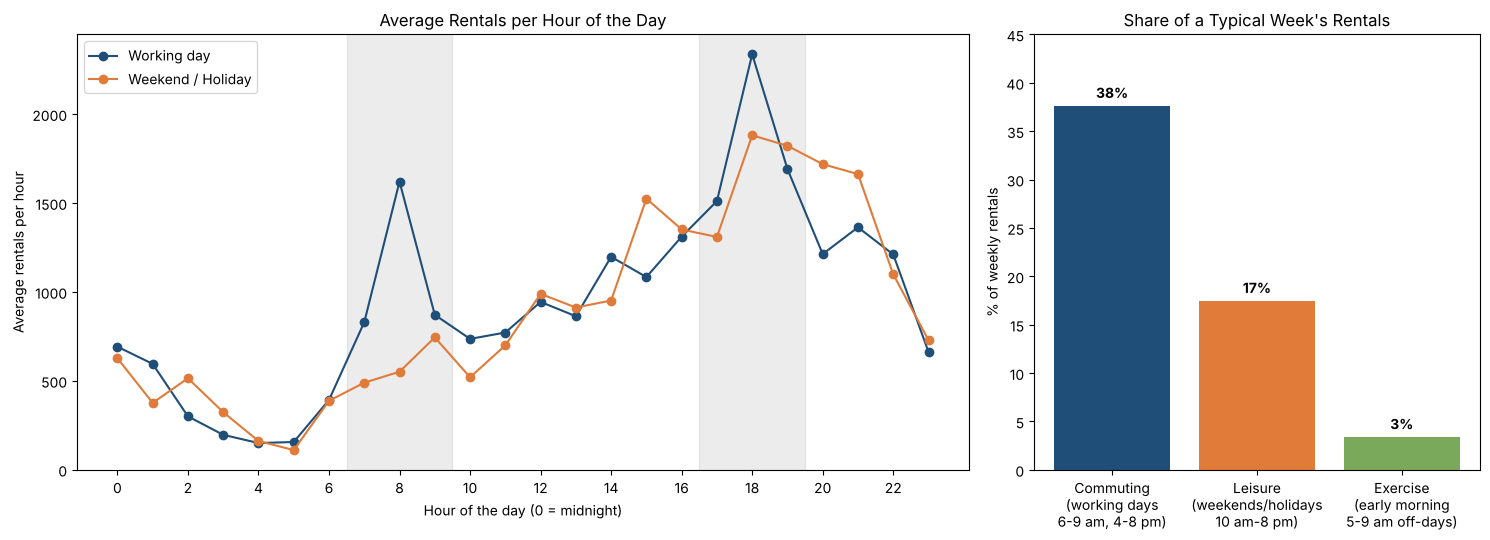

In [9]:
# side-by-side view: hourly demand curve and the share of weekly rentals by purpose
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (15, 5.5),
                       gridspec_kw = {'width_ratios': [2, 1]})


# left: hourly profile with the two commute windows shaded
for day, color in [('Working day', '#1f4e79'), ('Weekend / Holiday', '#e07b39')]:
    ax[0].plot(profile.index, profile[day], marker = 'o', color = color, label = day)

ax[0].axvspan(6.5, 9.5,   color = 'grey', alpha = 0.15)   # morning rush window
ax[0].axvspan(16.5, 19.5, color = 'grey', alpha = 0.15)   # evening rush window
ax[0].set_title('Average Rentals per Hour of the Day')
ax[0].set_xlabel('Hour of the day (0 = midnight)')
ax[0].set_ylabel('Average rentals per hour')
ax[0].set_xticks(range(0, 24, 2))
ax[0].legend()


# right: share of a typical week's rentals by trip purpose
ax[1].bar(purpose_share.index, purpose_share.values * 100,
          color = ['#1f4e79', '#e07b39', '#7aa95c'])
for i, value in enumerate(purpose_share.values * 100):
    ax[1].text(i, value + 0.8, f"{value:.0f}%", ha = 'center', fontweight = 'bold')
ax[1].set_title('Share of a Typical Week\'s Rentals')
ax[1].set_ylabel('% of weekly rentals')
ax[1].set_ylim(0, 45)


# rendering the figure
plt.tight_layout()
plt.show()

<strong>Reading the chart.</strong> The left panel shows the average number of rentals for each hour of the day, separately for working days (blue) and weekends or holidays (orange). Working days follow a two-peak commuter shape: demand jumps to about 1,620 rentals at 8 am and reaches the highest point of the whole week, about 2,340, at 6 pm, both inside the shaded rush windows. Weekends and holidays have no morning peak at all; at 8 am they average only about 550 rentals, roughly one third of a working day, and demand instead builds slowly through the afternoon and evening. The right panel turns these curves into a typical week (five working days and two off-days) and assigns each block of hours to the trip purpose that best explains it. Working-day commute windows account for about 38% of all weekly rentals, more than twice the share of weekend daytime leisure (about 17%) and roughly eleven times the early-morning exercise window (about 3%). The remaining 41% of rentals happen at hours that hourly data cannot tie to a single purpose, such as working-day lunchtimes and late evenings, so they are left unassigned rather than guessed.

In [10]:
# supporting evidence 1: how much busier the commute peaks are on working days
peaks = profile.loc[[8, 18]].round(0)
peaks['Working day / Off-day'] = (peaks['Working day'] / peaks['Weekend / Holiday']).round(2)
peaks

day_type,Weekend / Holiday,Working day,Working day / Off-day
Hour,,,
8,551.0,1620.0,2.94
18,1881.0,2337.0,1.24


In [11]:
# supporting evidence 2: holidays vs normal working days at the SAME hours of the day
holiday_hours = bikes[ bikes['holiday'] == 1 ]
workday_means = bikes[ bikes['offday'] == 0 ].groupby('Hour')['RENTALS'].mean()

holiday_ratio = holiday_hours['RENTALS'].sum() / workday_means[holiday_hours['Hour']].sum()
print(f"Holiday demand vs a normal working day (same hours): {holiday_ratio:.0%}")

Holiday demand vs a normal working day (same hours): 87%


In [12]:
# supporting evidence 3: does the morning commute pattern hold within EACH month?
morning = bikes[ bikes['Hour'].isin([7, 8, 9]) ].pivot_table(index   = 'Month',
                                                            columns = 'day_type',
                                                            values  = 'RENTALS',
                                                            aggfunc = 'mean')

# ratio above 1 means working-day mornings are busier than off-day mornings
morning['Working / Off-day'] = morning['Working day'] / morning['Weekend / Holiday']
morning.loc[ ['Mar', 'Apr', 'May', 'June'] ].round({'Weekend / Holiday' : 0,
                                                    'Working day'       : 0,
                                                    'Working / Off-day' : 2})

day_type,Weekend / Holiday,Working day,Working / Off-day
Month,,,
Mar,355.0,681.0,1.92
Apr,628.0,940.0,1.49
May,537.0,1350.0,2.51
June,879.0,1529.0,1.74


<h3>Answer: Commuting is the dominant reason people rent bikes.</h3>

Commuting is by far the largest of the three purposes: working-day commute windows carry about 38% of a typical week's rentals, more than leisure (17%) and exercise (3%) combined. The timing is the clearest signature, because at 8 am a working day generates 2.9 times as many rentals as a weekend or holiday, a gap that only the trip to work can explain. This is not a seasonal artefact: within each month separately, working-day mornings (7 to 9 am) are 1.5 to 2.5 times busier than off-day mornings. Holidays act as a natural experiment, since removing work from an otherwise normal weekday lowers demand at the same hours to 87% of a regular working day, although only 21 holiday hours are available, so this figure is indicative. Leisure is real but secondary, filling weekend afternoons and evenings without ever creating a peak as sharp as the working-day morning rush, and exercise is the smallest purpose, since early weekend mornings are among the quietest periods of the week. The data does not record trip purpose, and 41% of rentals fall at hours that cannot be tied to one purpose, so we cannot prove that more than half of all trips are commutes; the evidence shows that commuting is the dominant and most consistent purpose, and the 38% share is a floor rather than a ceiling. External research points the same way: in Chicago's own Divvy system, member trips are strongly tied to weekday morning and afternoon commuting periods (Lu et al., 2026), and a study of 40 bikeshare schemes found that weekday use follows a two- or three-peak daily curve while weekend use peaks in the afternoon (Bean et al., 2021). In Washington, D.C., six in ten Capital Bikeshare members also reported using the system to travel to or from work (LDA Consulting, 2012). For Cook County, this means the system should be planned like public transport, with stations, rebalancing crews and bike availability sized for the 7 to 9 am and 5 to 7 pm working-day peaks rather than for weekend leisure.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part V: Task 2 - The Most Important Weather Factor (Linear Model)</h2>
Weather features sit on very different scales (temperature in what appear to be degrees Celsius, humidity in percent, visibility in the thousands), and the workbook does not document every unit, so raw coefficients cannot be compared. Each weather feature is therefore <strong>standardized</strong> (mean 0, standard deviation 1), with the scaler fitted on the training set only. A standardized coefficient then reads: <em>"rentals change by this many bikes per hour when the factor moves by one typical amount."</em> Three specifications are compared, the strictest of which holds the hour, month and type of day constant.

In [13]:
# all weather-related columns, including Dew Point (Snowfall is always 0 and is excluded)
weather_all = weather + ['Dew Point Temperature']


# calendar controls: hour of day, month and type of day
calendar_controls = pd.concat([hour_dummies, month_dummies, bikes[ ['offday'] ]], axis = 1)


# specification 1: all weather factors including Dew Point
sum_1, coef_1, loss_1 = standardized_weather_model(bikes[weather_all], y_rentals, weather_all,
                                                   'Weather only (with Dew Point)')

# specification 2: Dew Point removed (it is calculated from Temperature and Humidity)
sum_2, coef_2, loss_2 = standardized_weather_model(bikes[weather], y_rentals, weather,
                                                   'Weather only (no Dew Point)')

# specification 3: weather plus calendar controls, so weather is compared at the same hour, month and day type
sum_3, coef_3, loss_3 = standardized_weather_model(pd.concat([bikes[weather], calendar_controls], axis = 1),
                                                   y_rentals, weather,
                                                   'Weather + calendar controls')

pd.DataFrame([sum_1, sum_2, sum_3])

,Model,Training R2,Testing R2
0,Weather only (with Dew Point),0.5173,0.5080
1,Weather only (no Dew Point),0.5139,0.5031
2,Weather + calendar controls,0.7159,0.7301


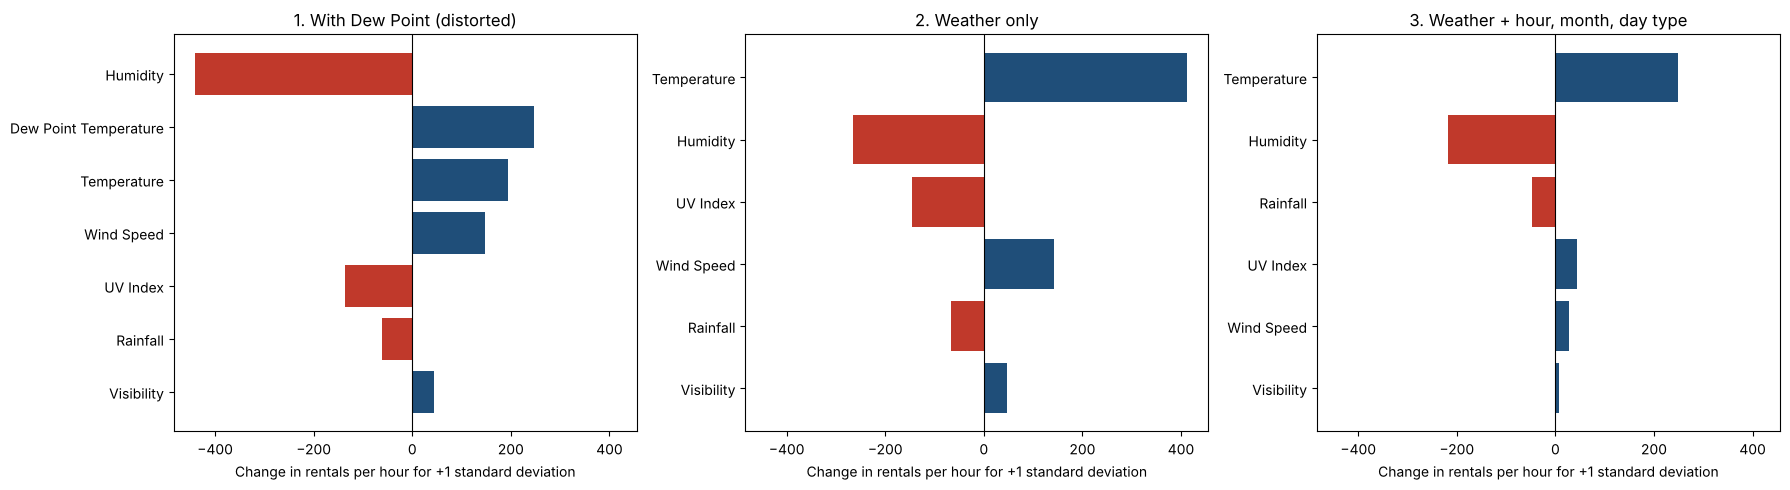

In [14]:
# standardized weather coefficients of the three specifications
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18, 5), sharex = True)

for axis, coefs, title in [(ax[0], coef_1, '1. With Dew Point (distorted)'),
                           (ax[1], coef_2, '2. Weather only'),
                           (ax[2], coef_3, '3. Weather + hour, month, day type')]:
    coefs = coefs.reindex(coefs.abs().sort_values().index)            # largest effect on top
    axis.barh(coefs.index, coefs.values,
              color = ['#c0392b' if v < 0 else '#1f4e79' for v in coefs.values])
    axis.axvline(0, color = 'black', linewidth = 0.8)
    axis.set_title(title)
    axis.set_xlabel('Change in rentals per hour for +1 standard deviation')


# rendering the figure
plt.tight_layout()
plt.show()

<strong>Reading the chart.</strong> The three panels show standardized coefficients from linear models; a longer bar means a larger effect on rentals for a typical change in that factor. In panel 1, which includes Dew Point, humidity appears strongest and temperature looks moderate, but this is an illusion: Dew Point is calculated from temperature and humidity, so the model splits their effects across overlapping variables. Once Dew Point is removed (panel 2), temperature clearly leads at about +413 rentals per hour for a typical rise in temperature (one standard deviation, about 7.5 degrees), well ahead of humidity at about -266. Panel 3 is the strictest test, comparing weather at the same hour, month and type of day, and temperature still leads (+248) ahead of humidity (-217). The margin narrows in panel 3 because month already captures part of temperature's seasonal rise from March to June, so what remains is the effect of warmer or cooler days within the same month. UV Index changes sign from negative to positive once the hour of the day is held constant, which confirms that its negative value in panel 2 simply reflected midday being quieter than the evening peak.

In [15]:
# drop-one check: testing R-square lost when each factor is removed, in both clean specifications
pd.DataFrame({'Weather only'                 : loss_2.round(3),
              'Weather + calendar controls'  : loss_3.round(3),
              'One standard deviation equals': bikes[weather].std().round(1)})\
  .sort_values('Weather only', ascending = False)

,Weather only,Weather + calendar controls,One standard deviation equals
Temperature,0.299,0.023,7.5
Humidity,0.051,0.019,21.9
UV Index,0.023,0.002,1.0
Wind Speed,0.015,0.000,1.0
Rainfall,0.006,0.005,1.5
Visibility,0.001,0.000,630.4


In [16]:
# rain: rare but severe - comparing rainy and dry hours
rain_effect = bikes.groupby('rain')['RENTALS'].agg(['count', 'mean']).round(0)
rain_effect.index = ['Dry hours', 'Rainy hours']
rain_effect

,count,mean
Dry hours,618,1033.0
Rainy hours,60,116.0


<h3>Answer: Temperature is the most important weather factor.</h3>

Temperature ranks first in all three linear specifications. In the weather-only model, removing temperature cuts testing R-square from 0.503 to about 0.20, a loss of 0.30, while no other factor costs more than 0.05. Even after controlling for hour, month and type of day, temperature remains first (losing it costs 0.023 against 0.019 for humidity), though by a narrower margin because month already reflects much of the seasonal warming. Rain is the most damaging condition when it happens, with rainy hours averaging about 116 rentals against 1,033 in dry hours (89% fewer), but it falls in only 60 of the 678 hours, so over the season it explains less of the variation in demand than temperature does. This distinction matters, because a 40-city comparison of nearly 100 million bikeshare trips found precipitation to be the stronger weather factor overall, while usage rose with temperature up to about 27 to 28 °C (Bean et al., 2021); in this spring sample, where rain was rare, temperature is the factor that moves demand most often. The real-world logic is simple: when March mornings sit near freezing, temperature decides whether a ride feels pleasant or punishing for every type of rider, from commuters to weekend riders. A Montréal study likewise found that a doubling of temperature was associated with a 43% to 50% rise in ridership, with the effect turning negative above about 28 °C in high humidity (Miranda-Moreno & Nosal, 2011). For the County, the temperature forecast should set the size of the fleet on the street each day, while rain alerts should trigger short-term actions such as pausing rebalancing until a downpour passes.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part VI: Task 3 - When Is Demand Low Enough for Maintenance? (Regression Tree)</h2>
The tree uses only information the client knows ahead of time: the hour, the forecast, the calendar and the month. It is pruned (<code>max_depth = 4</code>, <code>min_samples_leaf = 8</code>) so that every terminal node represents a recurring situation rather than a single unusual hour.

In [17]:
# tuning the tree with cross-validation INSIDE the training set (depth fixed at 4 for readability)
tree_features = ['Hour', 'Temperature', 'Humidity', 'Wind Speed', 'Visibility',
                 'UV Index', 'Rainfall', 'offday', 'rush', 'month_num']

tuning = []
for leaf_size in [5, 8, 10, 15, 20, 25]:
    summary, _ = run_model(DecisionTreeRegressor(max_depth = 4, min_samples_leaf = leaf_size,
                                                 random_state = 702),
                           bikes[tree_features], y_rentals, f'depth 4, leaf {leaf_size}')
    tuning.append(summary)

# the testing columns are shown for transparency; the choice is explained below
pd.DataFrame(tuning).drop(columns = 'X-Features')

,Model,CV R2 (train only),Training R2,Testing R2,Abs. Gap
0,"depth 4, leaf 5",0.5891,0.7612,0.6790,0.0823
1,"depth 4, leaf 8",0.6002,0.7465,0.7081,0.0384
2,"depth 4, leaf 10",0.6090,0.7424,0.6854,0.0569
3,"depth 4, leaf 15",0.6134,0.7223,0.6391,0.0832
4,"depth 4, leaf 20",0.5779,0.6867,0.6347,0.0520
5,"depth 4, leaf 25",0.5607,0.6776,0.6366,0.0409


<strong>Reading the tuning table.</strong> Before reading any maintenance windows, we chose the tree's settings with 5-fold cross-validation inside the training set, so the testing hours played no part in fitting or tuning. The depth is fixed at four levels so that every path can be read as a short, plain-language rule. Cross-validated R-square is very similar for leaf sizes of 5 to 15 hours (0.589 to 0.613), so the data does not strongly favour one setting over another. Within that near-tie, a minimum of 8 hours per leaf scores within 0.013 of the best cross-validated value and is the only top-tier setting whose train-test gap meets the 0.05 stability standard (0.038). Larger leaves of 20 or 25 hours are stable but clearly weaker, because they merge quiet and busy hours into the same group. We therefore use a depth of 4 with at least 8 hours per leaf for Task 3.

In [18]:
# x-features for the maintenance tree (interpretable, forecastable inputs)
tree_features = ['Hour', 'Temperature', 'Humidity', 'Wind Speed', 'Visibility',
                 'UV Index', 'Rainfall', 'offday', 'rush', 'month_num']


# developing ONE pruned regression tree
summary_tree, maintenance_tree = run_model(DecisionTreeRegressor(max_depth        = 4,
                                                                 min_samples_leaf = 8,
                                                                 random_state     = 702),
                                           bikes[tree_features], y_rentals,
                                           'Regression tree (depth 4, leaf 8)')

pd.DataFrame([summary_tree])

,Model,X-Features,CV R2 (train only),Training R2,Testing R2,Abs. Gap
0,"Regression tree (depth 4, leaf 8)",10,0.6002,0.7465,0.7081,0.0384


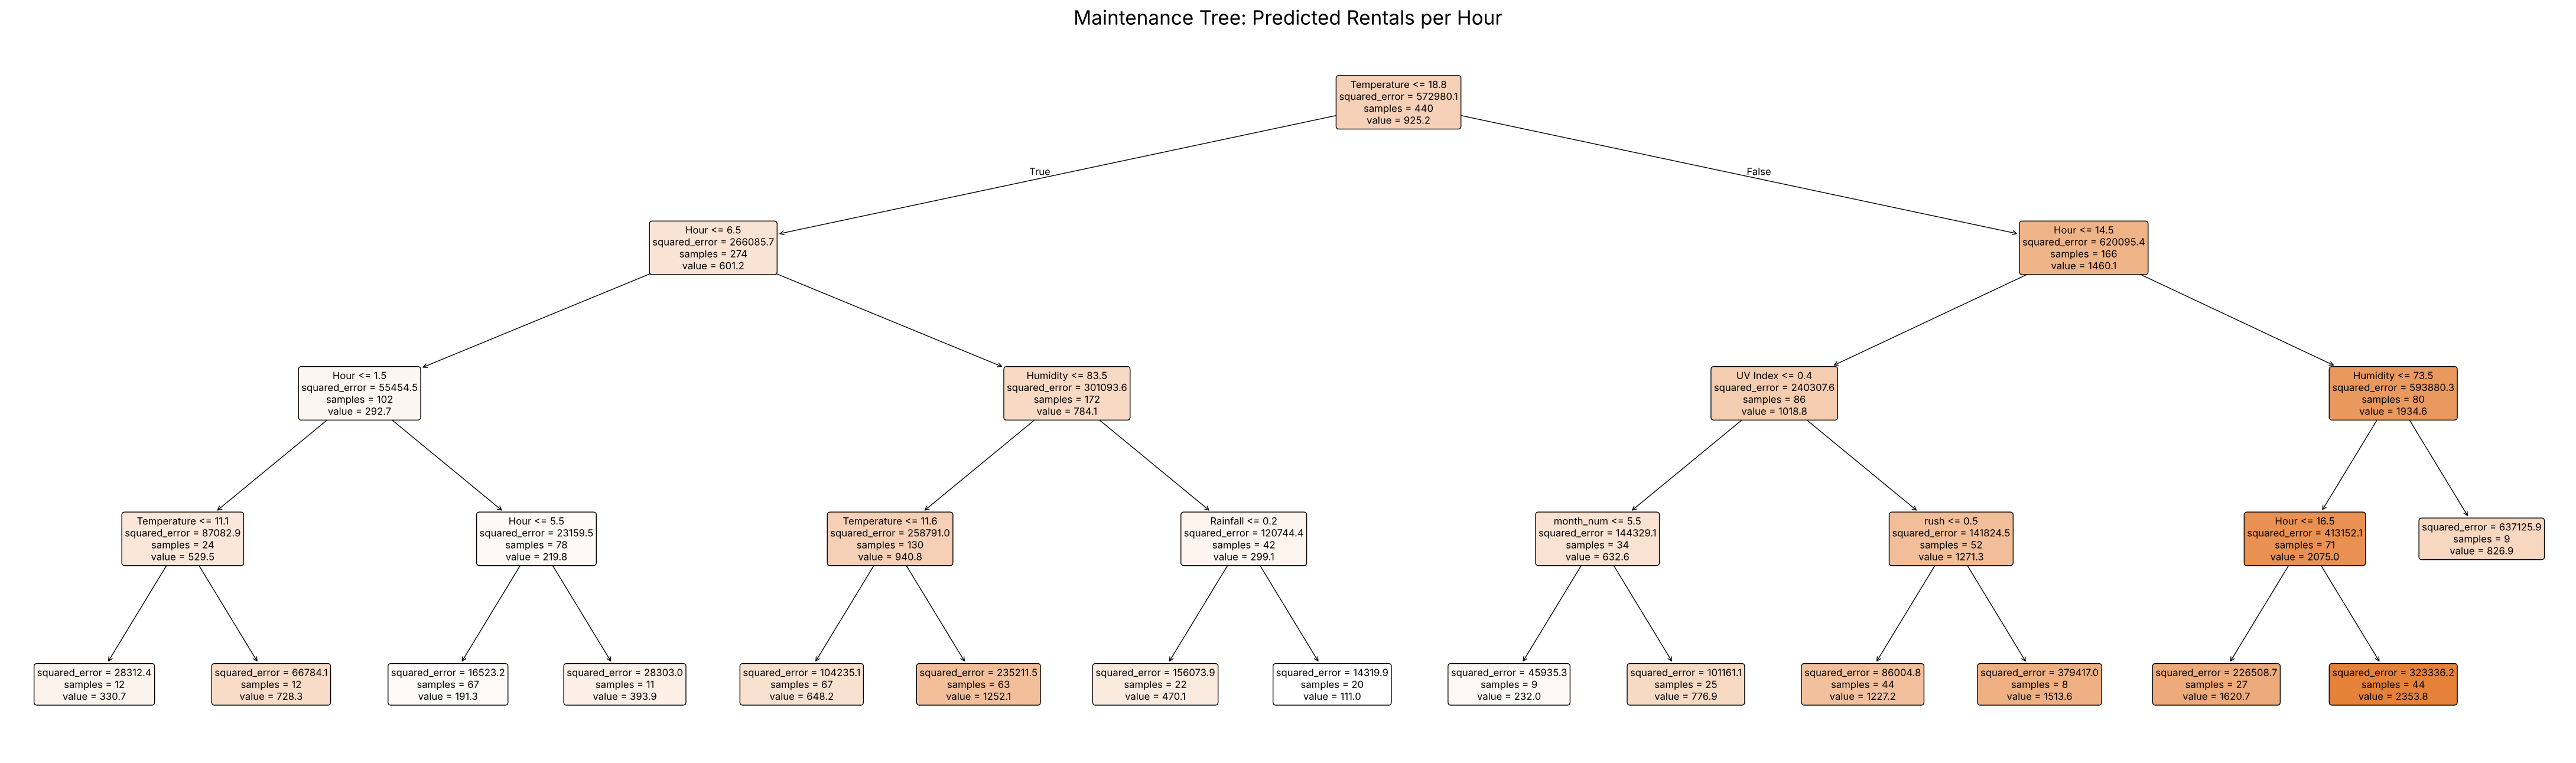

In [19]:
# plotting the tree (large canvas so every node can be read)
plt.figure(figsize = (56, 16))


# filled colors: darker nodes predict more rentals
plot_tree(decision_tree = maintenance_tree,
          feature_names = tree_features,
          filled        = True,
          rounded       = True,
          fontsize      = 12,
          precision     = 1)


# title and rendering
plt.title('Maintenance Tree: Predicted Rentals per Hour', fontsize = 24)
plt.show()

<strong>Reading the tree.</strong> The tree learns from the 440 training hours and divides them into 15 groups (terminal nodes), each with its own predicted average number of rentals; darker boxes predict higher demand. The very first split is temperature at 18.8 °C, which independently confirms the Task 2 finding that temperature is the strongest weather driver. On cooler hours, the next split is the time of day: before 6:30 am demand collapses, especially between 2 and 6 am. On cooler hours later in the day, humidity above 83.5% combined with measurable rain (Rainfall above 0.2) produces the lowest demand of the entire tree. On warmer hours, the busiest group is warm, relatively dry afternoons and evenings after 4:30 pm at about 2,350 rentals per hour, while warm mornings are split by whether it is a working-day rush hour. The tree is stable (training R-square 0.746, testing 0.708, gap 0.038), so the groups it finds are recurring patterns rather than noise; the selected maintenance nodes are identified in the table below by their node numbers.

In [20]:
# applying the SAME tree to all 678 hours to see where each hour lands
bikes['leaf'] = maintenance_tree.apply(bikes[tree_features])
rules         = leaf_rules(maintenance_tree, tree_features)


# one row per terminal node: size, predicted demand and share of the full dataset
leaves = bikes.groupby('leaf').agg(hours          = ('RENTALS', 'size'),
                                   avg_rentals    = ('RENTALS', 'mean'))

leaves['predicted']   = [maintenance_tree.tree_.value[leaf][0][0] for leaf in leaves.index]
leaves['share']       = leaves['hours'] / len(bikes)
leaves                = leaves.sort_values('predicted')                 # lowest demand first
leaves['cumulative']  = leaves['share'].cumsum()


# plain-language summary of the two lowest-demand paths and their union
selected = leaves.head(n = 2)


# translating each path into operating terms (a path that tests Rainfall is the rainy-day window)
def plain_language(leaf):
    if any('Rainfall' in rule for rule in rules[leaf]):
        return 'Cool, very humid, rainy hours after 6:30 am'
    return 'Cool nights (about 19 C or below), 2:00-5:59 am'


# one row per selected path
maintenance_table = pd.DataFrame({
    'Tree node'          : selected.index,
    'Plain-language path': [plain_language(leaf) for leaf in selected.index],
    'Hours'              : selected['hours'].values,
    'Dataset coverage'   : (selected['share'] * 100).round(1).astype(str) + '%',
    'Avg rentals / hour' : selected['avg_rentals'].round(0).values})

# adding the combined row (union of the two paths)
union = bikes['leaf'].isin(selected.index)
maintenance_table.loc[len(maintenance_table)] = ['Both', 'Combined maintenance windows', union.sum(),
                                                 f"{union.mean() * 100:.1f}%",
                                                 round(bikes.loc[union, 'RENTALS'].mean(), 0)]
maintenance_table.set_index('Tree node')

,Plain-language path,Hours,Dataset coverage,Avg rentals / hour
Tree node,,,,
15,"Cool, very humid, rainy hours after 6:30 am",29,4.3%,104.0
7,"Cool nights (about 19 C or below), 2:00-5:59 am",93,13.7%,191.0
Both,Combined maintenance windows,122,18.0%,170.0


In [21]:
# full decision path of the two lowest-demand nodes, exactly as the tree defines them
for rank, leaf in enumerate(leaves.index[:2], start = 1):
    print(f"Path {rank} (node {leaf}): " + "  AND  ".join(rules[leaf]))

Path 1 (node 15): Temperature <= 18.8  AND  Hour > 6.5  AND  Humidity > 83.5  AND  Rainfall > 0.2
Path 2 (node 7): Temperature <= 18.8  AND  Hour <= 6.5  AND  Hour > 1.5  AND  Hour <= 5.5


<strong>Reading the table.</strong> The table summarizes the two terminal nodes with the lowest predicted demand after the same tree is applied to all 678 hours, together with their combined coverage. The rainy-hours path averages about 104 rentals per hour but covers only 29 hours, or 4.3% of the dataset, which would not meet the 10% requirement on its own. The cool-nights path averages about 191 rentals per hour and covers 93 hours, or 13.7% of the dataset. Together the two paths cover 122 distinct hours, or 18.0% of the dataset, comfortably above the minimum of 68 hours that 10% requires. The next-lowest node in the tree predicts about 232 rentals per hour and covers only 1.9% of the hours, so adding it would not change the recommendation. During the 122 selected hours the system averages 170 rentals per hour, compared with 1,123 in all other hours, and these hours account for just 3.2% of all rentals.

In [22]:
# demand during the two maintenance windows compared with all other hours
window = bikes['leaf'].isin(leaves.index[:2])          # True for hours in the two lowest nodes


# coverage, demand level and share of all rentals affected

print(f"Hours covered by the two paths : {window.sum()} of {len(bikes)} ({window.mean():.1%})")
print(f"Average rentals inside windows  : {bikes.loc[window,  'RENTALS'].mean():,.0f} per hour")
print(f"Average rentals outside windows : {bikes.loc[~window, 'RENTALS'].mean():,.0f} per hour")
print(f"Share of all rentals affected   : {bikes.loc[window, 'RENTALS'].sum() / bikes['RENTALS'].sum():.1%}")

Hours covered by the two paths : 122 of 678 (18.0%)
Average rentals inside windows  : 170 per hour
Average rentals outside windows : 1,123 per hour
Share of all rentals affected   : 3.2%


<h3>Answer: Two low-demand windows from the same tree cover 18% of the dataset.</h3>

The first is a planned window: on any night when the temperature is at or below about 19 °C, demand between 2:00 and 5:59 am averages roughly 190 rentals per hour, about one fifth of an average hour, and this path alone covers 13.7% of the dataset. In plain terms, this is "the middle of a cool night", which in this data describes every night in March and April, 88% of nights in May and about half of the nights in June. The second is an opportunistic window: during the day or evening, when it is cool, the air is saturated (humidity above 84%) and rain is falling, demand drops to about 100 rentals per hour, adding another 4.3% of the dataset. In plain terms, this is "a cold, rainy day", when most riders stay home anyway. Together, the two windows cover 18.0% of all hours but only 3.2% of all rentals, so maintenance carried out in them affects very few riders. We recommend making 2 to 6 am the standard maintenance shift for routine work such as tire, brake and dock checks, scheduled every night through the spring. Cool, rainy days should serve as on-call windows for larger jobs that take many bikes off the street at once, since weather forecasts give one to two days of notice. As nights warm up in June, the overnight window shrinks, so the County should complete major maintenance in March to May, before summer demand peaks. Because the data contains no autumn or winter months, these windows should be re-estimated once that data is available, when low demand is likely to last much longer.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part VII: Final Model - Real-Time Demand Prediction</h2>
Candidate models are compared on the same train-test split. The rule is simple: <strong>the highest testing R-square among models with a train-test gap of 0.05 or less</strong>.

In [23]:
# x-feature sets for the candidates (built from the engineered features in Part III)
x_calendar = pd.concat([bikes[weather], hour_dummies, month_dummies,
                        bikes[ ['holiday', 'offday'] ]], axis = 1)

x_flags    = pd.concat([bikes[weather], hour_dummies, month_dummies,
                        bikes[ ['holiday', 'offday', 'rush', 'am_peak', 'pm_peak',
                                'rain', 'humid_high'] ]], axis = 1)

x_final    = pd.concat([x_flags, bikes[ ['pleasant_evening'] ]], axis = 1)


# candidate: simple benchmark with hour as one number (0-23) instead of categories
x_numeric_hour = pd.concat([bikes[weather + ['Hour', 'holiday', 'offday']], month_dummies], axis = 1)
summary, _ = run_model(LinearRegression(), x_numeric_hour, y_rentals, 'Linear - benchmark (numeric hour)')
candidates = [summary, summary_tree]


# candidate: weather only (the Task 2 model)
summary, _ = run_model(LinearRegression(), bikes[weather], y_rentals, 'Linear - weather only')
candidates.append(summary)

# candidate: weather plus calendar information
summary, _ = run_model(LinearRegression(), x_calendar, y_rentals, 'Linear - weather + hour + month + day type')
candidates.append(summary)


# candidate: a fully grown tree, to show what overfitting looks like
summary, _ = run_model(DecisionTreeRegressor(random_state = 702), bikes[tree_features], y_rentals,
                       'Regression tree (unpruned)')
candidates.append(summary)


# candidate: calendar plus commute and weather flags
summary, _ = run_model(LinearRegression(), x_flags, y_rentals,
                       'Linear - + commute and weather flags')
candidates.append(summary)


# candidate: adding the pleasant-evening flag (final model)
summary_final, final_model = run_model(LinearRegression(), x_final, y_rentals,
                                       'Linear - FINAL (+ pleasant evening)')
candidates.append(summary_final)


# comparison table, best testing score first
comparison = pd.DataFrame(candidates)
comparison['Stable (gap <= 0.05)'] = comparison['Abs. Gap'] <= 0.05
comparison.sort_values('Testing R2', ascending = False)

,Model,X-Features,CV R2 (train only),Training R2,Testing R2,Abs. Gap,Stable (gap <= 0.05)
6,Linear - FINAL (+ pleasant evening),40,0.6795,0.7904,0.8273,0.0369,True
5,Linear - + commute and weather flags,39,0.6653,0.7611,0.7882,0.0271,True
3,Linear - weather + hour + month + day type,34,0.4757,0.7160,0.7302,0.0142,True
1,"Regression tree (depth 4, leaf 8)",10,0.6002,0.7465,0.7081,0.0384,True
0,Linear - benchmark (numeric hour),12,0.3392,0.5915,0.5803,0.0112,True
4,Regression tree (unpruned),10,0.5550,1.0000,0.5699,0.4301,False
2,Linear - weather only,6,0.3626,0.5139,0.5031,0.0108,True


In [24]:
# robustness check: re-scoring the two best linear models on 30 other random splits
robustness = {}

for name, x_set in [('Commute and weather flags', x_flags), ('FINAL (+ pleasant evening)', x_final)]:

    test_scores = []
    for seed in range(1, 31):                                  # 30 different random splits
        x_tr, x_te, y_tr, y_te = train_test_split(x_set, y_rentals, test_size = 0.35, random_state = seed)
        test_scores.append(LinearRegression().fit(x_tr, y_tr).score(x_te, y_te))

    # average and worst testing R-square across the 30 splits
    robustness[name] = {'Average testing R2' : np.mean(test_scores),
                        'Lowest testing R2'  : np.min(test_scores)}

pd.DataFrame(robustness).T.round(4)

,Average testing R2,Lowest testing R2
Commute and weather flags,0.7198,0.4889
FINAL (+ pleasant evening),0.7599,0.5161


<strong>Reading the robustness check.</strong> A single train-test split can flatter a model by chance, so we re-scored the two best linear models on 30 other random splits of the same data. The pleasant-evening flag improves the average testing R-square from 0.720 to 0.760, so its gain is not an accident of one particular split. It also lifts the worst-case split from 0.489 to 0.516, which means the improvement holds even when the testing set happens to contain the hardest hours. The averages sit below the 0.827 achieved on the course split, which is a reminder that a 238-hour test set produces some variation in scores from one split to the next. For the client, the honest expectation is therefore an R-square of roughly 0.76 on average, with 0.83 achieved on the course benchmark split.

<strong>Reading the comparison.</strong> The table compares seven candidate models on the same train-test split and adds a cross-validated R-square computed inside the training set only, so the choice does not depend on the testing hours. The benchmark with hour as a single number reaches only 0.580, because demand does not rise in a straight line through the day, while treating each hour as its own category lifts the linear model to 0.730; month is used rather than season because season is fully determined by month in this file. The unpruned tree is the clearest case of overfitting, memorizing the training hours perfectly (R-square 1.00) but falling to 0.57 on new hours, a gap of 0.43, so it is rejected, and the pruned tree from Task 3 is stable but reaches only 0.708 because it can predict just 15 different values. Four business flags (working-day 8 am, working-day 5 to 7 pm, any rain, and humidity of 80% or more) raise testing R-square to 0.788, and a single "pleasant evening" flag (15 °C or warmer between 4 pm and 10:59 pm) lifts it to 0.827, the best of all candidates. The same model also has the highest cross-validated R-square inside the training set (0.680), so it would have been selected without looking at the testing hours at all. Its absolute gap of 0.037 is within the 0.05 limit, and its testing score is slightly above its training score, which means it predicts new hours as well as the hours it learned from.

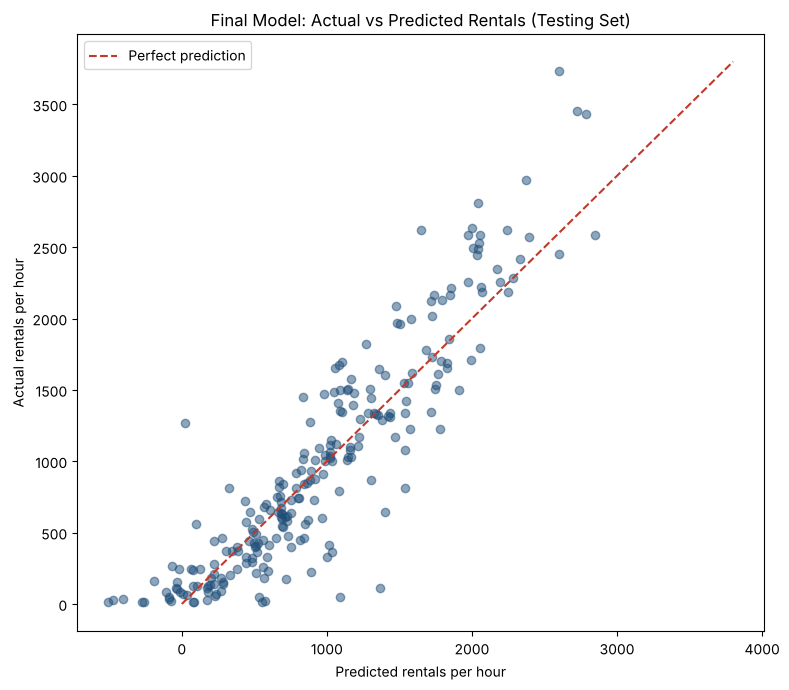

Average absolute error: 239 rentals per hour


In [25]:
# predictions of the final model on the hours it has never seen (testing set)
x_train, x_test, y_train, y_test = train_test_split(x_final, y_rentals,
                                                    test_size = 0.35, random_state = 702)
final_pred = final_model.predict(x_test)


# actual vs predicted rentals
fig, ax = plt.subplots(figsize = (8, 7))

ax.scatter(final_pred, y_test, alpha = 0.5, color = '#1f4e79')
ax.plot([0, 3800], [0, 3800], color = '#c0392b', linestyle = '--', label = 'Perfect prediction')
ax.set_title('Final Model: Actual vs Predicted Rentals (Testing Set)')
ax.set_xlabel('Predicted rentals per hour')
ax.set_ylabel('Actual rentals per hour')
ax.legend()


# rendering the plot
plt.tight_layout()
plt.show()


# typical size of an hourly prediction error on the testing set
print(f"Average absolute error: {np.mean(np.abs(y_test - final_pred)):,.0f} rentals per hour")

<strong>Reading the chart.</strong> Each dot is one of the 238 testing hours that the model never saw during training, plotted by predicted rentals (horizontal) against actual rentals (vertical). Dots close to the red dashed line are accurate predictions, and the cloud follows the line from quiet nights all the way to the busiest evenings. The typical error is about 239 rentals per hour (median 156), against an average of about 1,000 rentals per hour in the testing set. Errors grow in the busiest hours: when actual demand exceeds 1,500 rentals, the model under-predicts by about 280 rentals on average, so peak stations should hold a safety buffer of bikes. For 16 of the quietest night hours the model predicts slightly negative values, a known limitation of linear models, so a live system should simply set any negative forecast to zero.

In [26]:
# translating the coefficients into business scenarios (change in rentals per hour)
coef     = pd.Series(final_model.coef_, index = x_final.columns)
avg_rain = bikes.loc[bikes['rain'] == 1, 'Rainfall'].mean()     # typical rainfall when it rains


# each scenario combines the coefficients that switch on together
effects = pd.Series({
    'Working day vs off-day, 8 am'          : coef['rush'] + coef['am_peak'] - coef['offday'],
    'Working day vs off-day, 5-7 pm'        : coef['rush'] + coef['pm_peak'] - coef['offday'],
    'Rain in the hour (typical shower)'     : coef['rain'] + coef['Rainfall'] * avg_rain,
    'Very humid hour (80% or more)'         : coef['humid_high'],
    'Pleasant evening (15 C+, 4-11 pm)'     : coef['pleasant_evening'],
    '5 degrees C warmer'                    : coef['Temperature'] * 5,
    'June vs March'                         : coef['month_June'] - coef['month_Mar']
})

effects.round(0).to_frame('Change in rentals per hour')

,Change in rentals per hour
"Working day vs off-day, 8 am",914.0
"Working day vs off-day, 5-7 pm",-36.0
Rain in the hour (typical shower),-451.0
Very humid hour (80% or more),-260.0
"Pleasant evening (15 C+, 4-11 pm)",601.0
5 degrees C warmer,81.0
June vs March,391.0


In [27]:
# documenting the final model: model type and feature groups
print(f"Final model : {type(final_model).__name__}() from scikit-learn, {x_final.shape[1]} x-features")
print("Weather     :", ', '.join(weather))
print("Calendar    : 23 hour dummies (base = midnight), 3 month dummies (base = April), holiday, offday")
print("Flags       : rush, am_peak, pm_peak, rain, humid_high, pleasant_evening")

Final model : LinearRegression() from scikit-learn, 40 x-features
Weather     : Temperature, Humidity, Wind Speed, Visibility, UV Index, Rainfall
Calendar    : 23 hour dummies (base = midnight), 3 month dummies (base = April), holiday, offday
Flags       : rush, am_peak, pm_peak, rain, humid_high, pleasant_evening


<h3>Final model: linear regression with weather, hour, month, commute flags and a pleasant-evening flag (testing R-square 0.827, gap -0.037).</h3>

We recommend this linear model for real-time prediction because it has the highest testing R-square of all stable candidates (0.827), its gap of -0.037 is within the 0.05 limit, and its advantage over the previous best linear model holds across 30 alternative splits. It also outperforms the best stable regression tree by 0.12, and every input is known in advance: the clock, the calendar and a standard weather forecast. The scenario table translates the model into operating terms: at 8 am a working day brings about 910 more rentals than the same hour on a weekend or holiday, the clearest commuting effect in the data. A pleasant evening adds about 600 rentals per hour, and once it is accounted for, working-day and weekend evenings are almost identical (a difference of about 40 rentals), which shows that the evening peak depends on comfortable weather, not on the day of the week. Rain removes about 450 rentals in a typical shower, a very humid hour removes about 260 more, and June runs about 390 rentals per hour above March. Within a single model, these effects confirm the story of Tasks 1 to 3: commuting creates the morning peak, and weather decides how big the evening becomes. In real time, the model can run on current weather readings to predict the coming hour, or on forecast weather to plan a day ahead, in which case errors in the weather forecast add to the model's own error. Because the model is linear, any planner can see why a forecast went up or down, which builds trust in its numbers. Its main limitation is coverage, since it learned only from March to June, so it should be retrained with autumn and winter data before it is used year-round.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part VIII: Recommendations for Cook County</h2>
1. **Plan for commuters first.** Rebalance before 7 am and again before 5 pm on working days, filling stations in residential areas in the morning and freeing up docks near offices and transit hubs for arrivals; this is when the system earns most of its rides.
2. **Make 2 to 6 am the default maintenance shift from March to May.** This window covers 13.7% of hours with demand at about one fifth of normal, and it can be scheduled weeks in advance.
3. **Use cool, rainy days for large maintenance jobs.** These hours carry the lowest demand in the dataset (about 100 rentals per hour) and are visible one to two days ahead in the forecast.
4. **Feed the weather forecast into fleet decisions every morning.** Temperature should set the size of the fleet on the street, a forecast of a dry evening at 15 °C or warmer should trigger extra bikes at evening hotspots from 4 pm (about 600 extra rentals per hour), and rain alerts should pause rebalancing until the weather clears.
5. **Fix the data before going live.** Confirm the holiday coding and the "UV Index" column, investigate the 0% humidity reading, and collect September to February data so the model can be retrained for the full year. Station-level data and member versus casual counts would also let the County measure trip purpose directly instead of inferring it from the time of day.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Modeling Rules Checklist</h2>
| Rule | How this notebook meets it |
|---|---|
| Model types | Only `LinearRegression()` and `DecisionTreeRegressor()` from scikit-learn. `StandardScaler` is used only to rescale inputs for Task 2 and is not a model |
| No polynomial or rooted x-variables | All x-features are original columns, dummy variables or yes/no flags built from thresholds (for example, the pleasant-evening flag). There are no squares, roots, logs or exponents |
| y-variable not on the x-side | `RENTALS` is used only as y. No feature is built from it, and `ID` is excluded |
| Processing time | The full notebook runs in well under 60 seconds (about 6 seconds on our machine) |
| Error-free and commented | Runs top to bottom without errors, with at least one comment for every five lines of code |
| Train-test gap ≤ 0.05 | Final model absolute gap = 0.037 (training 0.790, testing 0.827) |
| Model selection discipline | Tree settings and model choice confirmed with 5-fold cross-validation inside the training set; the testing set is used only to report final scores. Scaling is fitted on training data only |

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>References</h2>
Bean, R., Pojani, D., & Corcoran, J. (2021). How does weather affect bikeshare use? A comparative analysis of forty cities across climate zones. *Journal of Transport Geography, 95*, Article 103155. https://doi.org/10.1016/j.jtrangeo.2021.103155

LDA Consulting. (2012). *Capital Bikeshare 2011 member survey report*. https://libraryarchives.metro.net/DPGTL/harvested/2011-Capital-bikeshare-member-survey.pdf

Lu, J., Li, Z., & Guo, Q. (2026). Exploring the determinants of bike-sharing member trips with explainable machine learning: Insights from Chicago's Divvy system. *Computational Urban Science, 6*(1), Article 22. https://doi.org/10.1007/s43762-026-00254-9

Miranda-Moreno, L. F., & Nosal, T. (2011). Weather or not to cycle: Temporal trends and impact of weather on cycling in an urban environment. *Transportation Research Record, 2247*(1), 42-52. https://doi.org/10.3141/2247-06

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>AI Usage Acknowledgment</h2>
[Edit this statement so it accurately describes your own use of AI.]

This notebook was developed with the assistance of Claude (Anthropic), an AI assistant, which was used to explore the dataset, draft code and written analysis, and locate external sources. All code was run and checked by the author, every figure quoted in the text was verified against the notebook's output, and each external source was checked against the original publication. Link to the AI conversation: [add link].